# Exploratory Data Analysis: India Housing Prices
**Project:** Real Estate Investment Advisor: Predicting Property Profitability & Future Value
**Data:** `data/processed/housing_clean.csv` (250,000 listings, produced by `src/preprocess.py` from `india_housing_prices.csv`)

This notebook answers the 20 EDA questions from the project brief, plus the extra questions on area, infrastructure and crime.
Prices are in **INR lakhs** (1 lakh = 100,000). Price per sq ft is shown in **INR**.

**How to run:** open this notebook from the project folder (or its `notebooks/` subfolder) and run all cells.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

CSV = next(p for p in [Path("data/processed/housing_clean.csv"), Path("../data/processed/housing_clean.csv")] if p.exists())
df = pd.read_csv(CSV)
AMENITIES = ["Clubhouse", "Garden", "Gym", "Playground", "Pool"]
spread = lambda s: s.max() / s.min() - 1      # gap between highest and lowest group average
print(df.shape)

(250000, 49)


## 0. Data overview and quality checks

In [2]:
display(df[["State","City","Locality","Property_Type","BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_INR",
            "Year_Built","Furnished_Status","Availability_Status","Good_Investment","Future_Price_5Y_Lakhs"]].head())
print("States:", df.State.nunique(), "| Cities:", df.City.nunique(), "| Locality labels:", df.Locality.nunique())
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate listings:", int(df.drop(columns="ID").duplicated().sum()))
df[["BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_INR","Age_of_Property","Nearby_Schools","Nearby_Hospitals"]].describe().T

,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_INR,Year_Built,Furnished_Status,Availability_Status,Good_Investment,Future_Price_5Y_Lakhs
0,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,"10,332.49",1990,Furnished,Ready_to_Move,0,672.59
1,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,"8,270.73",2008,Unfurnished,Under_Construction,1,274.87
2,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,"5,046.40",1997,Semi-furnished,Ready_to_Move,0,237.94
3,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,"10,955.49",1991,Furnished,Ready_to_Move,0,392.47
4,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,"3,792.25",2002,Semi-furnished,Ready_to_Move,0,235.10


States: 20 | Cities: 42 | Locality labels: 500


Missing values: 0 | Duplicate listings: 0


,count,mean,std,min,25%,50%,75%,max
BHK,"250,000.00",3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00","2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt_INR,"250,000.00","13,058.28","13,071.85",202.25,"4,802.84","9,244.75","15,987.39","99,182.00"
Age_of_Property,"250,000.00",18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,"250,000.00",5.50,2.88,1.00,3.00,5.00,8.00,10.00
Nearby_Hospitals,"250,000.00",5.50,2.87,1.00,3.00,5.00,8.00,10.00


In [3]:
print(f"Rows where the original Floor_No exceeded Total_Floors: {int(df.Floor_Data_Flag.sum()):,} ({df.Floor_Data_Flag.mean():.1%})")
print("Listings per (City, Locality) pair:", df.groupby("Locality_Key").size().describe()[["mean","min","max"]].round(0).to_dict())
print("Listings per Locality label      :", df.groupby("Locality").size().describe()[["mean","min","max"]].round(0).to_dict())

Rows where the original Floor_No exceeded Total_Floors: 116,304 (46.5%)
Listings per (City, Locality) pair: {'mean': 12.0, 'min': 1.0, 'max': 29.0}
Listings per Locality label      : {'mean': 500.0, 'min': 441.0, 'max': 567.0}


**Data-quality notes**
- No missing values and no duplicate listings.
- About **46.5%** of rows had a floor number higher than the building's total floors, which is impossible. Floors were capped during cleaning and the issue is kept in `Floor_Data_Flag`.
- The raw `Price_per_SqFt` was in lakhs and rounded to 2 decimals, so it was recomputed in INR (`Price_per_SqFt_INR`).
- Locality names repeat across all 42 cities. A city-locality pair has only about 12 listings, so locality analysis uses the 500 labels (about 500 listings each).

## A. Price and size

### Q1. What is the distribution of property prices?

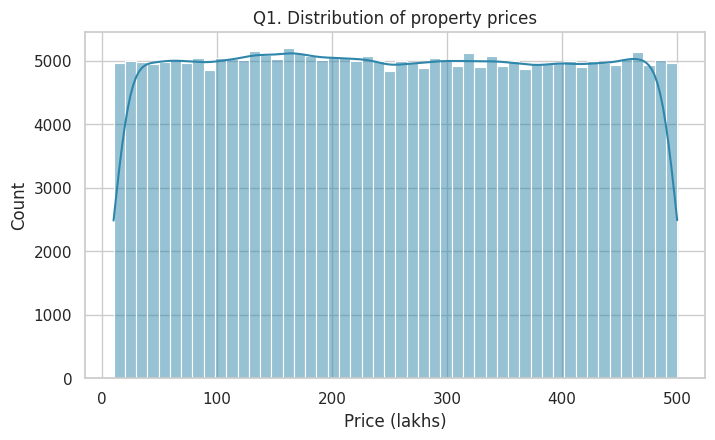

count   250,000.00
mean        254.60
std         141.30
min          10.00
25%         132.60
50%         253.90
75%         376.90
max         500.00
Skew: 0.01


In [4]:
plt.figure(figsize=(8,4.5)); sns.histplot(df.Price_in_Lakhs, bins=50, kde=True, color="#2E86AB")
plt.xlabel("Price (lakhs)"); plt.title("Q1. Distribution of property prices"); plt.show()
print(df.Price_in_Lakhs.describe().round(1).to_string()); print("Skew:", round(df.Price_in_Lakhs.skew(), 2))

**Takeaway:** Prices run from 10 to 500 lakhs and are almost flat (uniform), with skew near zero. Real markets are usually right-skewed, which is the first hint that this dataset is synthetic.

### Q2. What is the distribution of property sizes?

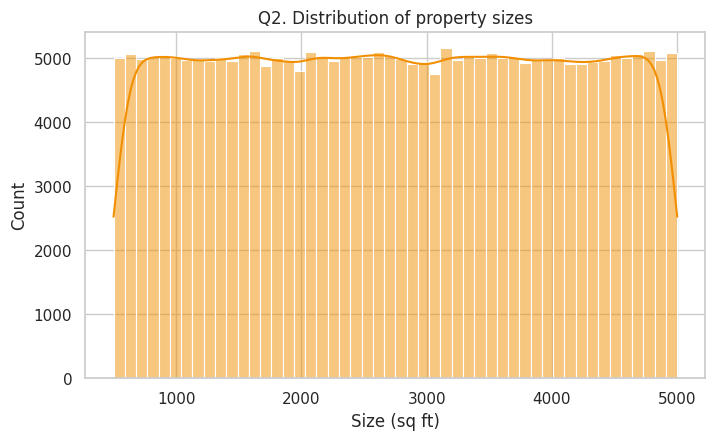

count   250,000.00
mean      2,750.00
std       1,301.00
min         500.00
25%       1,623.00
50%       2,747.00
75%       3,874.00
max       5,000.00

Average size by BHK:
BHK
1   2,750.00
2   2,752.00
3   2,750.00
4   2,753.00
5   2,745.00


In [5]:
plt.figure(figsize=(8,4.5)); sns.histplot(df.Size_in_SqFt, bins=50, kde=True, color="#F18F01")
plt.xlabel("Size (sq ft)"); plt.title("Q2. Distribution of property sizes"); plt.show()
print(df.Size_in_SqFt.describe().round(0).to_string())
print("\nAverage size by BHK:"); print(df.groupby("BHK").Size_in_SqFt.mean().round(0).to_string())

**Takeaway:** Sizes are also roughly uniform (500 to 5,000 sq ft). A 1 BHK averages about the same size as a 5 BHK, which does not happen in real listings.

### Q3. How does price per sq ft vary by property type?

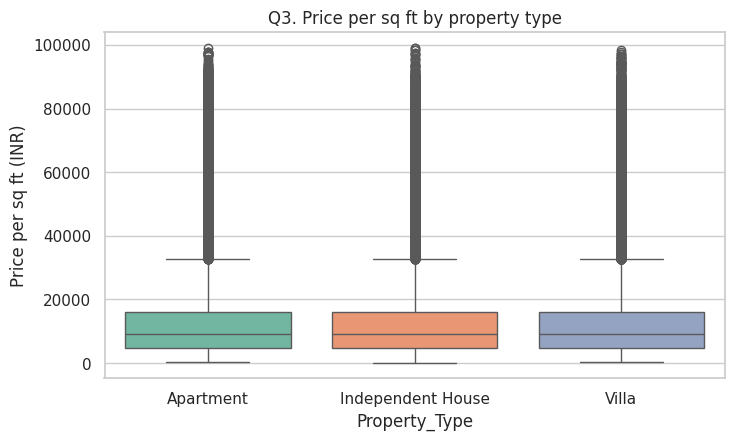

,mean,median
Property_Type,,
Apartment,"13,047.00","9,245.00"
Independent House,"13,102.00","9,305.00"
Villa,"13,026.00","9,190.00"


Gap between highest and lowest mean: 0.6%


In [6]:
plt.figure(figsize=(8,4.5)); sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt_INR", palette="Set2", hue="Property_Type", legend=False)
plt.ylabel("Price per sq ft (INR)"); plt.title("Q3. Price per sq ft by property type"); plt.show()
g = df.groupby("Property_Type").Price_per_SqFt_INR.agg(["mean","median"]).round(0); display(g)
print(f"Gap between highest and lowest mean: {spread(g['mean']):.1%}")

**Takeaway:** Apartments, independent houses and villas have almost the same price per sq ft (gap under 1%), so property type does not drive price here.

### Q4. Is there a relationship between property size and price?

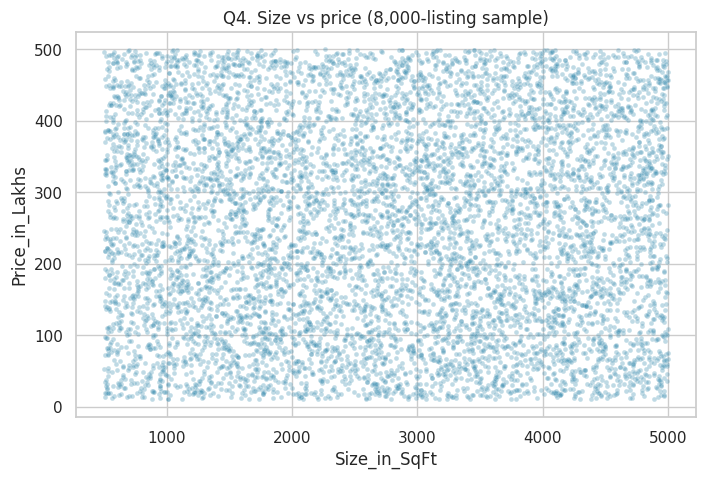

Correlation (size, price): -0.003


In [7]:
s = df.sample(8000, random_state=1)
plt.figure(figsize=(8,5)); sns.scatterplot(data=s, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=.3, s=12, color="#2E86AB")
plt.title("Q4. Size vs price (8,000-listing sample)"); plt.show()
print("Correlation (size, price):", round(df[["Size_in_SqFt","Price_in_Lakhs"]].corr().iloc[0,1], 3))

**Takeaway:** Correlation is about 0, so size does not explain price. In a real market this would normally be strongly positive.

### Q5. Are there outliers in price per sq ft, size or price?

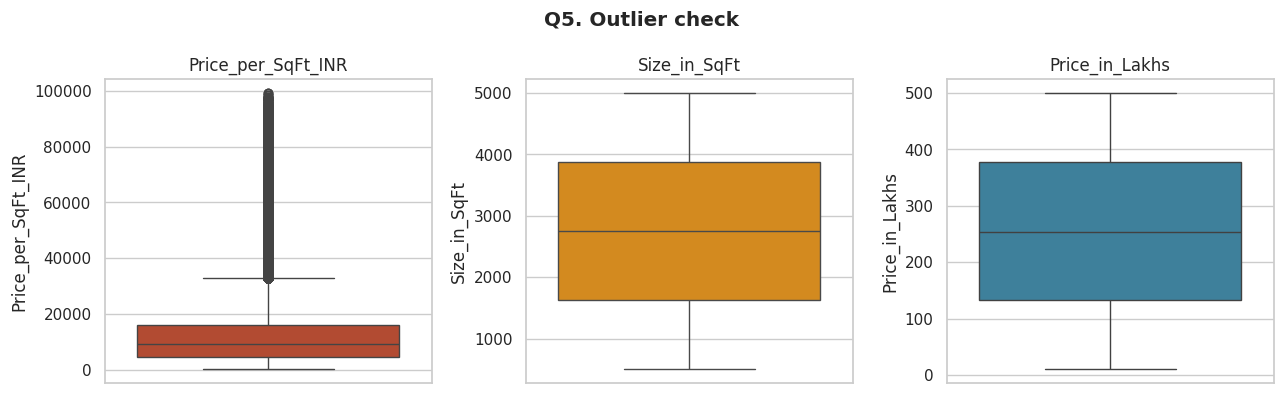

IQR outliers  | price per sq ft: 19,723 (7.9%) | size: 0 | price: 0
Outlier profile: avg size 841 sq ft, avg price 388 lakhs  (overall: 2,750 sq ft, 255 lakhs)


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c, col in zip(ax, ["Price_per_SqFt_INR","Size_in_SqFt","Price_in_Lakhs"], ["#C73E1D","#F18F01","#2E86AB"]):
    sns.boxplot(y=df[c], ax=a, color=col); a.set_title(c)
plt.suptitle("Q5. Outlier check", weight="bold"); plt.tight_layout(); plt.show()
o = df[df.PPSF_Outlier == 1]
print(f"IQR outliers  | price per sq ft: {len(o):,} ({len(o)/len(df):.1%}) | size: {int(df.Size_in_SqFt_Outlier.sum())} | price: {int(df.Price_in_Lakhs_Outlier.sum())}")
print(f"Outlier profile: avg size {o.Size_in_SqFt.mean():,.0f} sq ft, avg price {o.Price_in_Lakhs.mean():,.0f} lakhs  (overall: {df.Size_in_SqFt.mean():,.0f} sq ft, {df.Price_in_Lakhs.mean():,.0f} lakhs)")

**Takeaway:** Price and size are bounded, so they have no outliers. About 7.9% of listings are price-per-sq-ft outliers, and they are **small, expensive** listings. They were flagged, not removed.

## B. Location

### Q6. What is the average price per sq ft by state?

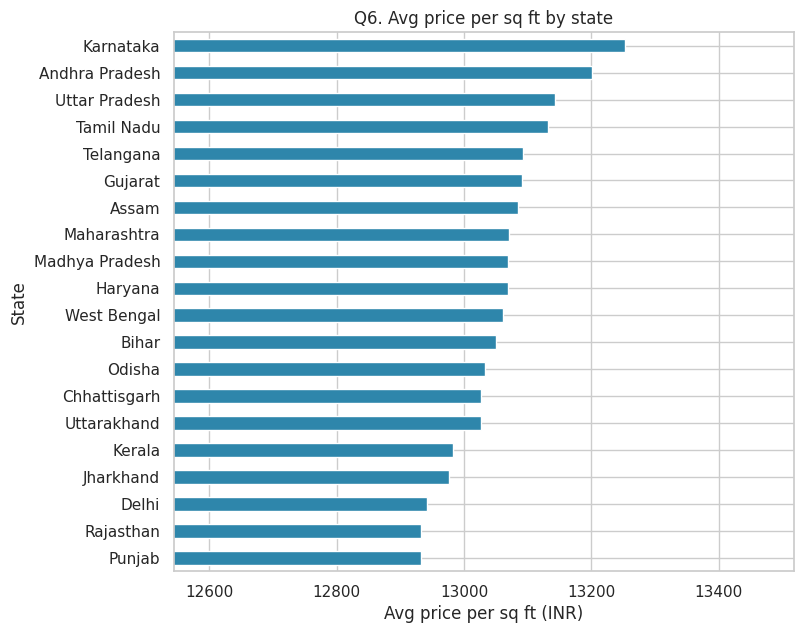

Highest: Karnataka (13,252) | Lowest: Punjab (12,931) | gap: 2.5%


In [9]:
st = df.groupby("State").Price_per_SqFt_INR.mean().sort_values()
plt.figure(figsize=(8,7)); st.plot.barh(color="#2E86AB"); plt.xlim(st.min()*.97, st.max()*1.02)
plt.xlabel("Avg price per sq ft (INR)"); plt.title("Q6. Avg price per sq ft by state"); plt.show()
print(f"Highest: {st.index[-1]} ({st.iloc[-1]:,.0f}) | Lowest: {st.index[0]} ({st.iloc[0]:,.0f}) | gap: {spread(st):.1%}")

**Takeaway:** States differ by only about 2.5% (axis starts near the minimum so the differences are visible). Karnataka is highest and Punjab lowest.

### Q7. What is the average property price by city?

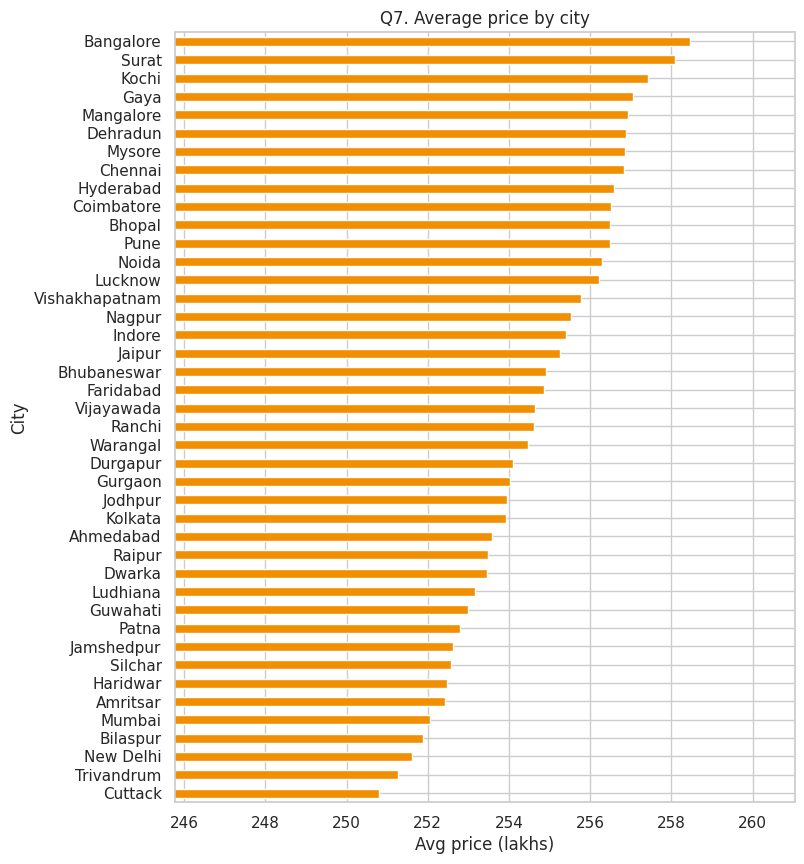

Highest: Bangalore (258.5 L) | Lowest: Cuttack (250.8 L) | gap: 3.1%
Mumbai: 252.1 | New Delhi: 251.6


In [10]:
ct = df.groupby("City").Price_in_Lakhs.mean().sort_values()
plt.figure(figsize=(8,10)); ct.plot.barh(color="#F18F01"); plt.xlim(ct.min()*.98, ct.max()*1.01)
plt.xlabel("Avg price (lakhs)"); plt.title("Q7. Average price by city"); plt.show()
print(f"Highest: {ct.index[-1]} ({ct.iloc[-1]:.1f} L) | Lowest: {ct.index[0]} ({ct.iloc[0]:.1f} L) | gap: {spread(ct):.1%}")
print("Mumbai:", round(ct["Mumbai"], 1), "| New Delhi:", round(ct["New Delhi"], 1))

**Takeaway:** All 42 cities are within about 3% of each other. Mumbai and New Delhi are among the *cheapest*, the opposite of a real market.

### Q8. What is the median age of properties by locality?

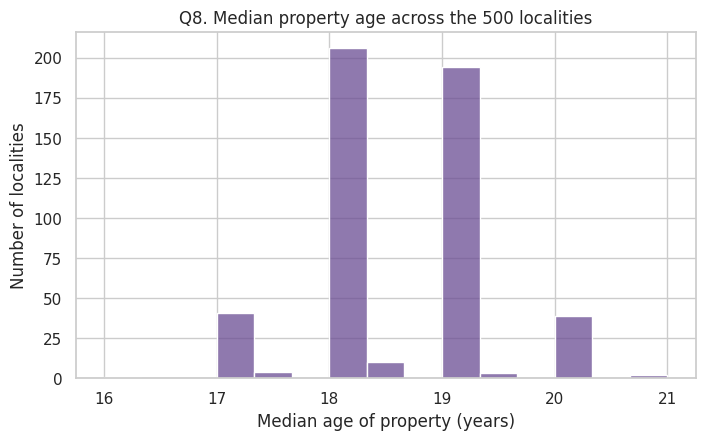

Range: 16 to 21 years | overall median: 18
Oldest: Locality_72 21.0 | Newest: Locality_443 16.0


In [11]:
lm = df.groupby("Locality").Age_of_Property.median().sort_values()
plt.figure(figsize=(8,4.5)); sns.histplot(lm, bins=15, color="#6A4C93")
plt.xlabel("Median age of property (years)"); plt.ylabel("Number of localities"); plt.title("Q8. Median property age across the 500 localities"); plt.show()
print(f"Range: {lm.min():.0f} to {lm.max():.0f} years | overall median: {df.Age_of_Property.median():.0f}")
print("Oldest:", lm.index[-1], lm.iloc[-1], "| Newest:", lm.index[0], lm.iloc[0])

**Takeaway:** Median age is 16 to 21 years in every locality, so no area is meaningfully older or newer. Analysed at label level because city-locality pairs have too few listings for stable medians.

### Q9. How is BHK distributed across cities?

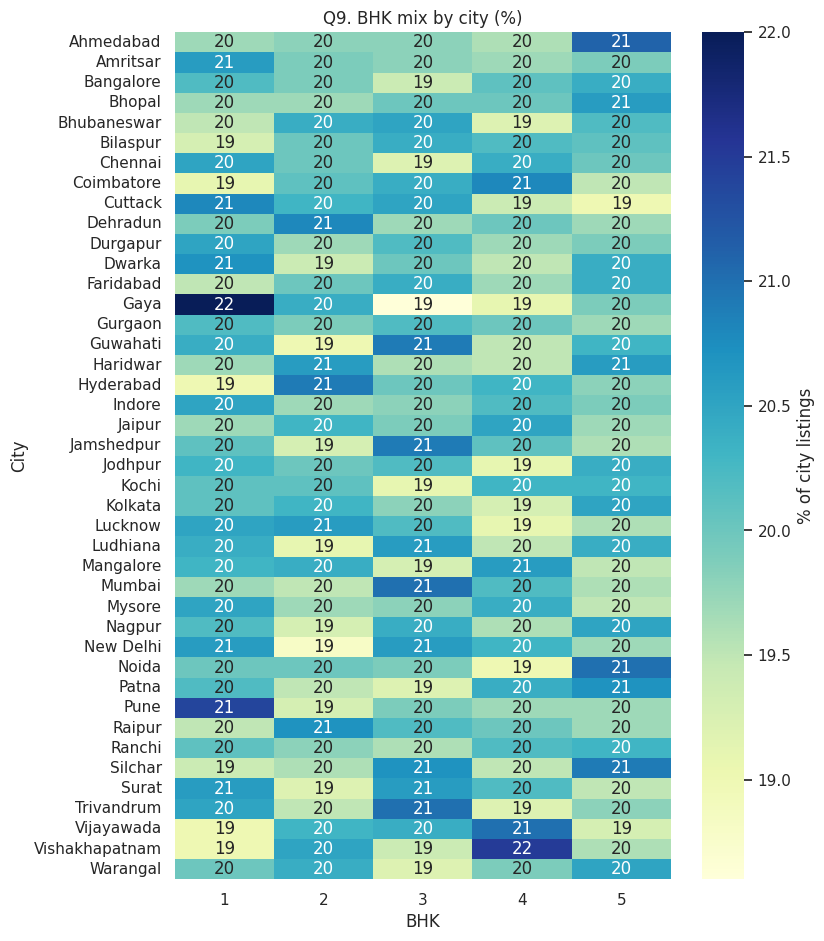

Each BHK share averages 20% (std 0.5)


In [12]:
bc = pd.crosstab(df.City, df.BHK, normalize="index") * 100
plt.figure(figsize=(8,11)); sns.heatmap(bc.round(1), annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of city listings"})
plt.title("Q9. BHK mix by city (%)"); plt.show()
print(f"Each BHK share averages {bc.values.mean():.0f}% (std {bc.values.std():.1f})")

**Takeaway:** Every city has a near-even split of 1 to 5 BHK (about 20% each).

### Q10. How do prices trend for the top 5 most expensive localities?

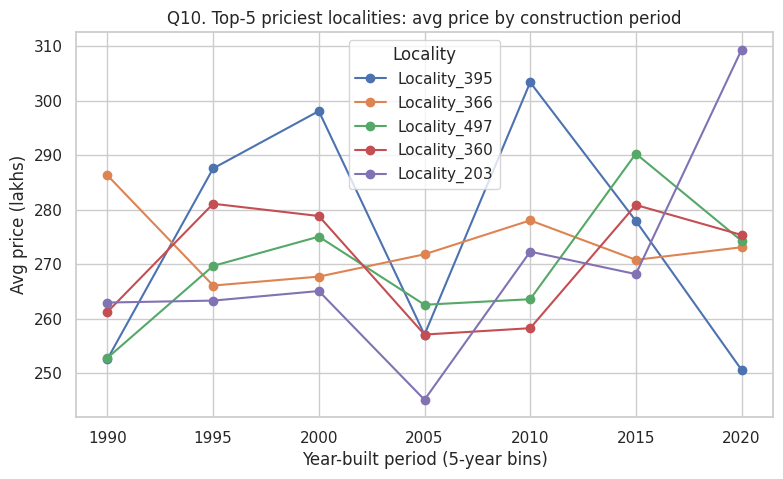

Locality
Locality_395   275.40
Locality_366   273.40
Locality_497   270.00
Locality_360   269.80
Locality_203   269.00

Top locality is 8% above the overall mean (255 L)


In [13]:
loc = df.groupby("Locality").Price_in_Lakhs.mean().nlargest(5)
sub = df[df.Locality.isin(loc.index)].copy(); sub["Build_Period"] = sub.Year_Built // 5 * 5
piv = sub.groupby(["Build_Period","Locality"]).Price_in_Lakhs.mean().unstack()[loc.index]
ax = piv.plot(marker="o", figsize=(9,5)); ax.set_ylabel("Avg price (lakhs)"); ax.set_xlabel("Year-built period (5-year bins)")
plt.title("Q10. Top-5 priciest localities: avg price by construction period"); plt.show()
print(loc.round(1).to_string()); print(f"\nTop locality is {loc.iloc[0]/df.Price_in_Lakhs.mean()-1:.0%} above the overall mean ({df.Price_in_Lakhs.mean():.0f} L)")

**Takeaway:** The data has **no listing dates**, so a real time trend is impossible. Construction period is used as a proxy. The lines swing up and down with no common direction (each point is about 70 listings, so this is sampling noise). The top localities are only about 8% above the average.

## C. Relationships and correlations

### Q11. How are numeric features correlated?

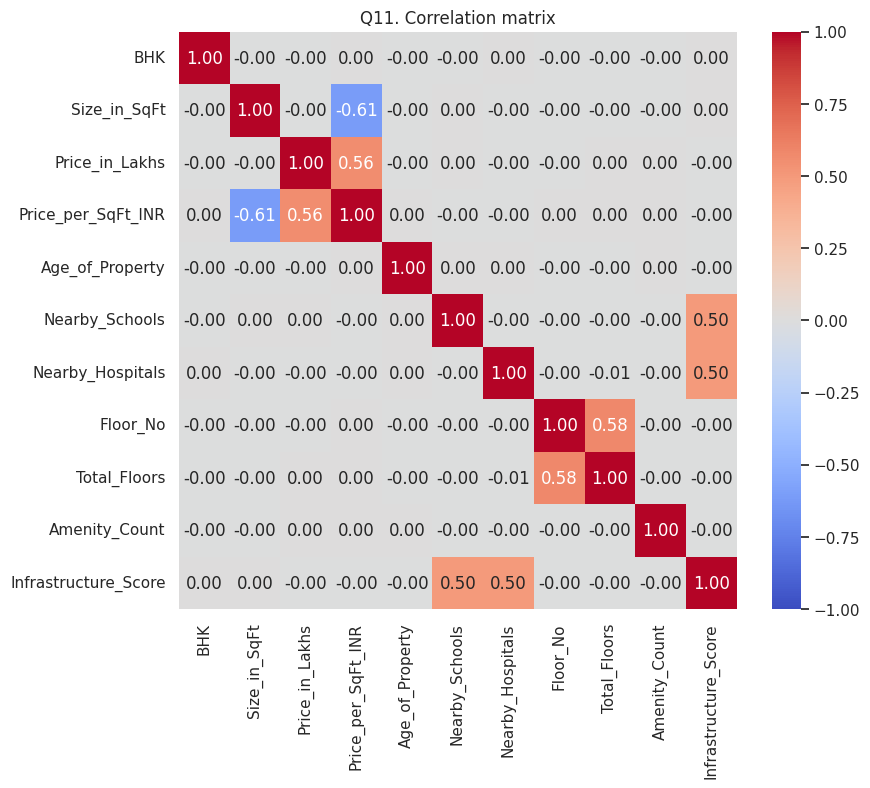

Largest |r| among independent raw features: 0.006  ('Nearby_Hospitals', 'Total_Floors')


In [14]:
numc = ["BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_INR","Age_of_Property","Nearby_Schools","Nearby_Hospitals",
        "Floor_No","Total_Floors","Amenity_Count","Infrastructure_Score"]
cm = df[numc].corr()
plt.figure(figsize=(9,7.5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Q11. Correlation matrix"); plt.show()
raw = ["BHK","Size_in_SqFt","Price_in_Lakhs","Age_of_Property","Nearby_Schools","Nearby_Hospitals","Total_Floors","Amenity_Count"]
r = df[raw].corr().abs().where(~np.eye(len(raw), dtype=bool)).stack()
print(f"Largest |r| among independent raw features: {r.max():.3f}  {r.idxmax()}")

**Takeaway:** The strong correlations are **mechanical**: price per sq ft is derived from price and size, Infrastructure_Score from schools and hospitals, and Floor_No was capped at Total_Floors. Among genuinely independent features the largest |r| is about 0.006.

### Q12. How are nearby schools related to price per sq ft?

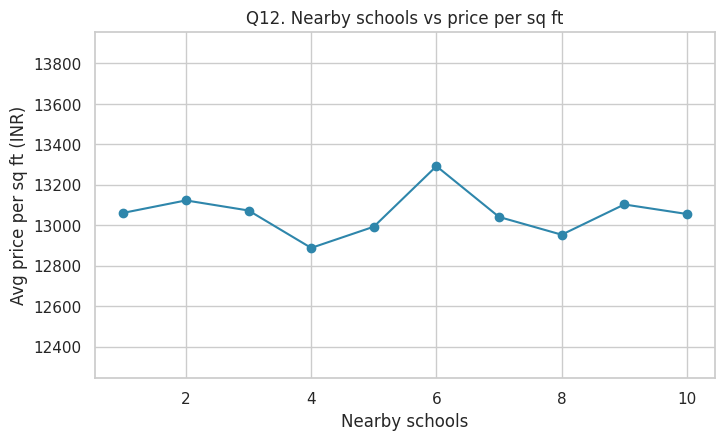

r = -0.0 | gap between groups: 3.1%


In [15]:
m = df.groupby("Nearby_Schools").Price_per_SqFt_INR.mean()
plt.figure(figsize=(8,4.5)); plt.plot(m.index, m.values, marker="o", color="#2E86AB"); plt.ylim(m.min()*.95, m.max()*1.05)
plt.xlabel("Nearby schools"); plt.ylabel("Avg price per sq ft (INR)"); plt.title("Q12. Nearby schools vs price per sq ft"); plt.show()
print("r =", round(df[["Nearby_Schools","Price_per_SqFt_INR"]].corr().iloc[0,1], 3), f"| gap between groups: {spread(m):.1%}")

**Takeaway:** No meaningful link (r is about 0). Group averages differ by about 3% at most, with no upward or downward trend.

### Q13. How are nearby hospitals related to price per sq ft?

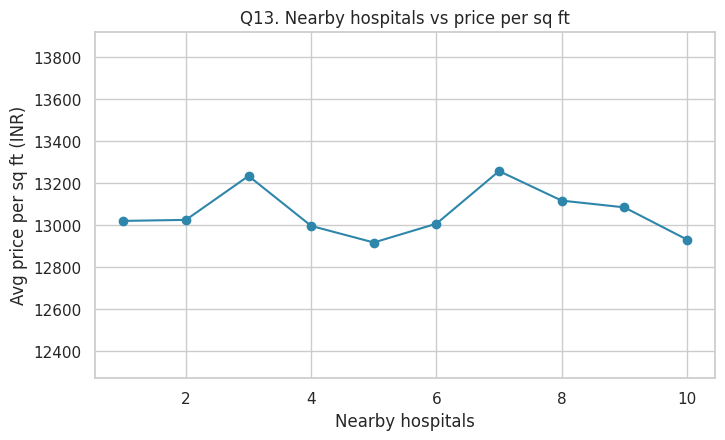

r = -0.0 | gap between groups: 2.6%


In [16]:
m = df.groupby("Nearby_Hospitals").Price_per_SqFt_INR.mean()
plt.figure(figsize=(8,4.5)); plt.plot(m.index, m.values, marker="o", color="#2E86AB"); plt.ylim(m.min()*.95, m.max()*1.05)
plt.xlabel("Nearby hospitals"); plt.ylabel("Avg price per sq ft (INR)"); plt.title("Q13. Nearby hospitals vs price per sq ft"); plt.show()
print("r =", round(df[["Nearby_Hospitals","Price_per_SqFt_INR"]].corr().iloc[0,1], 3), f"| gap between groups: {spread(m):.1%}")

**Takeaway:** Same picture as schools: no meaningful relationship.

### Q14. How do prices vary by furnishing status?

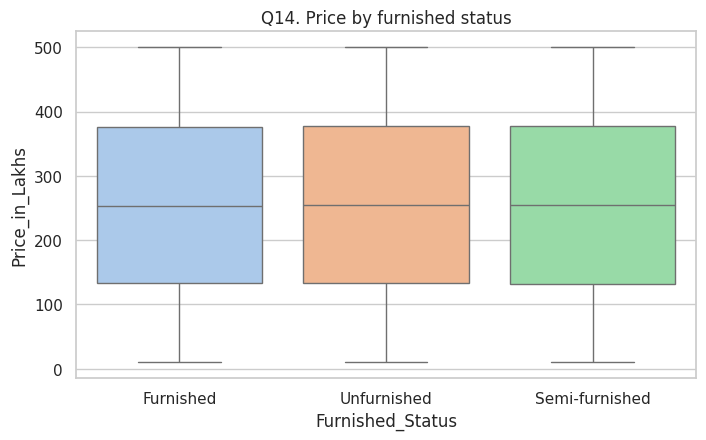

Furnished_Status
Furnished        254.40
Semi-furnished   254.30
Unfurnished      255.00
Name: Price_in_Lakhs, dtype: float64

Gap between highest and lowest: 0.3%


In [17]:
plt.figure(figsize=(8,4.5)); sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", palette="pastel", hue="Furnished_Status", legend=False)
plt.title("Q14. Price by furnished status"); plt.show()
m = df.groupby("Furnished_Status").Price_in_Lakhs.mean(); display(m.round(1))
print(f"Gap between highest and lowest: {spread(m):.1%}")

**Takeaway:** Furnishing carries no price premium here (gap about 0.3%).

### Q15. How does price per sq ft vary by facing direction?

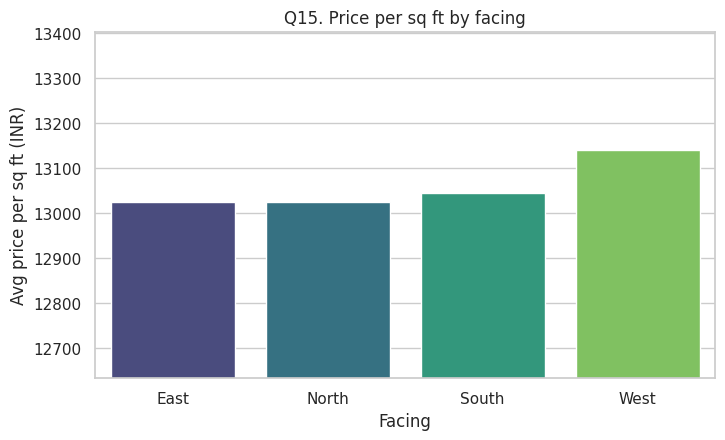

Facing
East    13,024.00
North   13,025.00
South   13,044.00
West    13,140.00 
Gap: 0.9%


In [18]:
m = df.groupby("Facing").Price_per_SqFt_INR.mean().sort_values()
plt.figure(figsize=(8,4.5)); sns.barplot(x=m.index, y=m.values, palette="viridis", hue=m.index, legend=False); plt.ylim(m.min()*.97, m.max()*1.02)
plt.ylabel("Avg price per sq ft (INR)"); plt.title("Q15. Price per sq ft by facing"); plt.show()
print(m.round(0).to_string(), f"\nGap: {spread(m):.1%}")

**Takeaway:** Facing direction changes price per sq ft by under 1%.

## D. Ownership, amenities and investment

### Q16 and Q17. How many properties per owner type and per availability status?

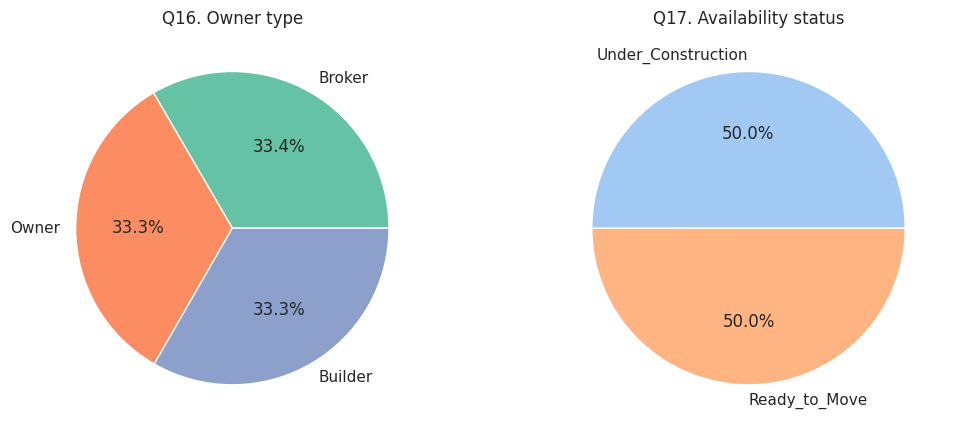

Owner_Type
Broker     83479
Owner      83268
Builder    83253

Availability_Status
Under_Construction    125035
Ready_to_Move         124965


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11,4.5))
vc = df.Owner_Type.value_counts(); ax[0].pie(vc, labels=vc.index, autopct="%1.1f%%", colors=sns.color_palette("Set2")); ax[0].set_title("Q16. Owner type")
vc2 = df.Availability_Status.value_counts(); ax[1].pie(vc2, labels=vc2.index, autopct="%1.1f%%", colors=sns.color_palette("pastel")); ax[1].set_title("Q17. Availability status")
plt.tight_layout(); plt.show()
print(vc.to_string()); print(); print(vc2.to_string())

**Takeaway:** Owner types are in near-equal thirds (Builder, Broker, Owner), and availability is about 50/50 between Ready_to_Move and Under_Construction.

### Q18. How does parking space relate to price?

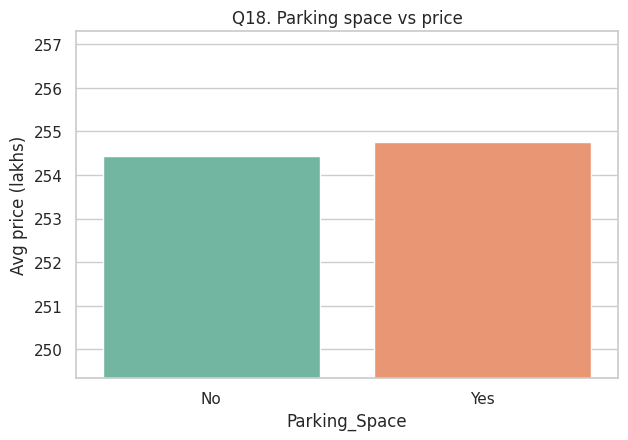

Parking_Space
No    254.40
Yes   254.70 
Gap: 0.1%


In [20]:
m = df.groupby("Parking_Space").Price_in_Lakhs.mean()
plt.figure(figsize=(7,4.5)); sns.barplot(x=m.index, y=m.values, palette="Set2", hue=m.index, legend=False); plt.ylim(m.min()*.98, m.max()*1.01)
plt.ylabel("Avg price (lakhs)"); plt.title("Q18. Parking space vs price"); plt.show()
print(m.round(1).to_string(), f"\nGap: {spread(m):.1%}")

**Takeaway:** Properties with and without parking have virtually the same average price (gap about 0.1%).

### Q19. How do amenities relate to price per sq ft?

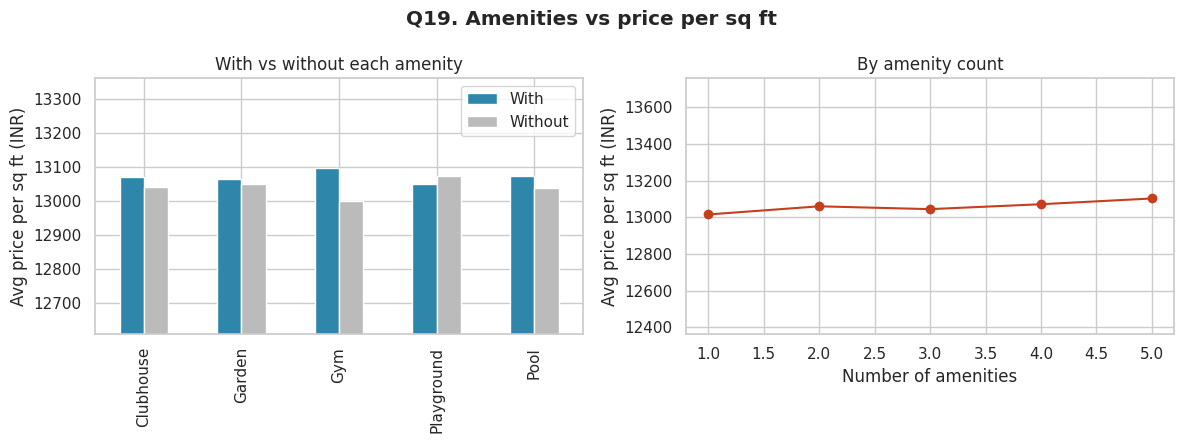

Clubhouse     +0.2%
Garden        +0.1%
Gym           +0.8%
Playground    -0.2%
Pool          +0.3%


In [21]:
am = pd.DataFrame({a: [df[df[f"Has_{a}"]==1].Price_per_SqFt_INR.mean(), df[df[f"Has_{a}"]==0].Price_per_SqFt_INR.mean()] for a in AMENITIES}, index=["With","Without"]).T
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
am.plot.bar(ax=ax[0], color=["#2E86AB","#BBBBBB"]); ax[0].set_ylabel("Avg price per sq ft (INR)"); ax[0].set_ylim(am.values.min()*.97, am.values.max()*1.02); ax[0].set_title("With vs without each amenity")
ac = df.groupby("Amenity_Count").Price_per_SqFt_INR.mean(); ax[1].plot(ac.index, ac.values, marker="o", color="#C73E1D")
ax[1].set_xlabel("Number of amenities"); ax[1].set_ylabel("Avg price per sq ft (INR)"); ax[1].set_ylim(ac.min()*.95, ac.max()*1.05); ax[1].set_title("By amenity count")
plt.suptitle("Q19. Amenities vs price per sq ft", weight="bold"); plt.tight_layout(); plt.show()
print((am.With / am.Without - 1).map("{:+.1%}".format).to_string())

**Takeaway:** Every amenity changes price per sq ft by less than 1% (Gym is the largest at about +0.8%; Playground is slightly negative), and there is no steady rise as the amenity count grows.

### Q20. How does public transport accessibility relate to price per sq ft and investment potential?

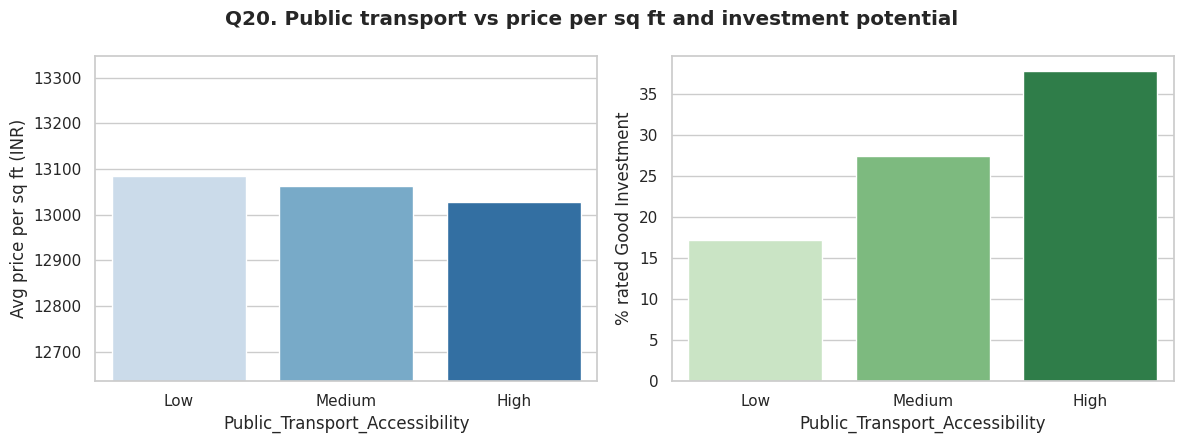

Public_Transport_Accessibility
Low      13,086.00
Medium   13,062.00
High     13,027.00
Public_Transport_Accessibility
Low      17.10
Medium   27.40
High     37.70


In [22]:
order = ["Low","Medium","High"]
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
m = df.groupby("Public_Transport_Accessibility").Price_per_SqFt_INR.mean().reindex(order)
sns.barplot(x=m.index, y=m.values, ax=ax[0], palette="Blues", hue=m.index, legend=False); ax[0].set_ylim(m.min()*.97, m.max()*1.02); ax[0].set_ylabel("Avg price per sq ft (INR)")
gi = df.groupby("Public_Transport_Accessibility").Good_Investment.mean().reindex(order) * 100
sns.barplot(x=gi.index, y=gi.values, ax=ax[1], palette="Greens", hue=gi.index, legend=False); ax[1].set_ylabel("% rated Good Investment")
plt.suptitle("Q20. Public transport vs price per sq ft and investment potential", weight="bold"); plt.tight_layout(); plt.show()
print(m.round(0).to_string()); print(gi.round(1).to_string())

**Takeaway:** Price per sq ft is nearly identical across transport levels, but the share of **Good Investments rises from about 17% (low) to 27% (medium) to 38% (high)**. That comes from the growth rule (transport raises the infrastructure score), not from market prices.

## E. Extra questions from the brief

### Does property size relate to investment return?

Correlation (size, projected annual growth): 0.002


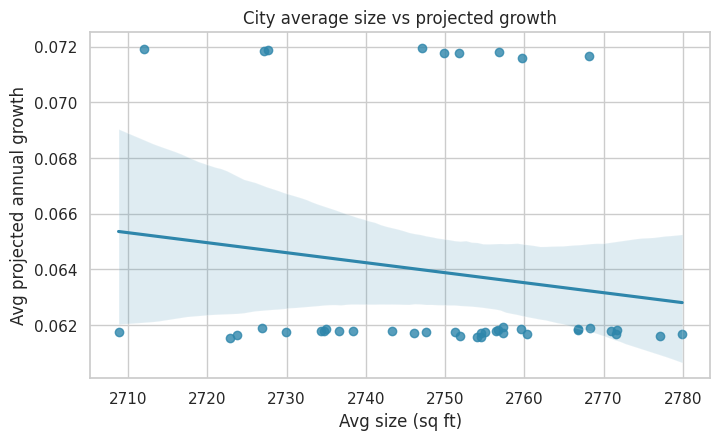

In [23]:
print("Correlation (size, projected annual growth):", round(df[["Size_in_SqFt","Annual_Growth_Rate"]].corr().iloc[0,1], 3))
m = df.groupby("City").agg(size=("Size_in_SqFt","mean"), ret=("Annual_Growth_Rate","mean"))
plt.figure(figsize=(8,4.5)); sns.regplot(data=m, x="size", y="ret", color="#2E86AB"); plt.xlabel("Avg size (sq ft)"); plt.ylabel("Avg projected annual growth")
plt.title("City average size vs projected growth"); plt.show()

**Takeaway:** No relationship. Projected growth depends on infrastructure, metro status, availability and age, not size.

### Does infrastructure relate to price or resale value?

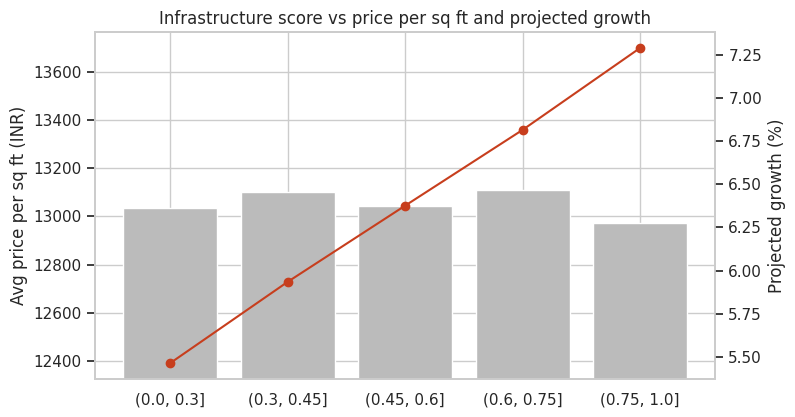

r (Infrastructure_Score, Price_in_Lakhs): -0.001


In [24]:
b = df.groupby(pd.cut(df.Infrastructure_Score, [0,.3,.45,.6,.75,1.0]), observed=True).agg(growth=("Annual_Growth_Rate","mean"), ppsf=("Price_per_SqFt_INR","mean"))
b.index = b.index.astype(str)
fig, ax1 = plt.subplots(figsize=(8,4.5)); ax1.bar(b.index, b.ppsf, color="#BBBBBB"); ax1.set_ylabel("Avg price per sq ft (INR)"); ax1.set_ylim(b.ppsf.min()*.95, b.ppsf.max()*1.05)
ax2 = ax1.twinx(); ax2.plot(b.index, b.growth*100, color="#C73E1D", marker="o"); ax2.set_ylabel("Projected growth (%)"); ax2.grid(False)
plt.title("Infrastructure score vs price per sq ft and projected growth"); plt.show()
print("r (Infrastructure_Score, Price_in_Lakhs):", round(df[["Infrastructure_Score","Price_in_Lakhs"]].corr().iloc[0,1], 3))

**Takeaway:** Infrastructure has almost no link to today's price, but it raises projected growth by design of the growth model.

### Does crime rate affect investment potential?

The dataset has **no crime-rate column**, so this cannot be tested directly. `Infrastructure_Score` (schools, hospitals, transport) is used as the area-quality proxy instead. A crime or safety index is listed as a next step.

## Summary
| Theme | Finding |
|---|---|
| Price and size | Both roughly uniform; size vs price r is about 0 |
| Outliers | 7.9% price-per-sq-ft outliers, all small and expensive listings |
| Location | 42 cities within about 3%; 20 states within about 2.5%; Mumbai and New Delhi are among the cheapest |
| Features | Schools, hospitals, furnishing, facing, parking, amenities and property type each move price by about 3% or less |
| Correlations | Only mechanical ones; largest among independent raw features is about 0.006 |
| Transport | No price effect, but Good-Investment share rises 17% to 38% because of the growth rule |
| Caveat | Features are independent of price, which is typical of synthetic data. The 5-year price and Good-Investment label are therefore rule-based (see `src/config.py`) |